In [3]:
import os
import json

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

ROOT = '../data/refer-kitti'
EXPR_DIR = ROOT + '/expression'
IMG_DIR  = ROOT + '/KITTI/training/image_02'
LBL_DIR  = ROOT + '/KITTI/labels_with_ids/image_02'

In [ ]:
seq = '0005'
frame = 10

label_path = LBL_DIR + '/' + seq + '/' + str(frame).zfill(6) + '.txt'
df = pd.read_csv(label_path, sep=' ', header=None, names=['cls', 'id', 'x', 'y', 'w', 'h'])

df

,cls,id,x,y,w,h
0,0,11,0.027375,0.456000,0.085346,0.122667
1,0,12,0.161031,0.469333,0.048309,0.077333
2,0,13,0.300322,0.472000,0.022544,0.042667
3,0,34,0.462158,0.472000,0.032206,0.096000


In [9]:
img_path = IMG_DIR + '/' + seq + '/' + str(frame).zfill(6) + '.png'
img = Image.open(img_path)
W, H = img.size

df['x'] = df['x'] * W
df['y'] = df['y'] * H
df['w'] = df['w'] * W
df['h'] = df['h'] * H
df


,cls,id,x,y,w,h
0,0,11,33.999750,171.000000,105.999732,46.000125
1,0,12,200.000502,175.999875,59.999778,28.999875
2,0,13,372.999924,177.000000,27.999648,16.000125
3,0,34,574.000236,177.000000,39.999852,36.000000


In [15]:
expr_path = EXPR_DIR + '/' + seq + '/black-cars-in-the-left.json'
with open(expr_path) as f:
    expr = json.load(f)

print('문장 :', expr['sentence'])
print('프레임의 대상 id:', expr['label'].get(str(frame), []))

문장 : black cars in the left
프레임의 대상 id: [13]


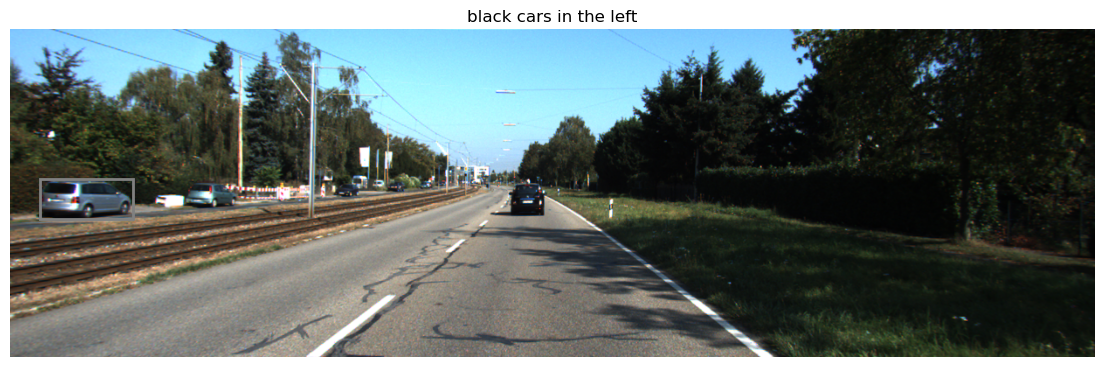

In [ ]:
targets = expr['label'].get(str(frame), [])

fig, ax = plt.subplots(figsize=(14,5))
ax.imshow(img)

for i in range(len(df)) :
    row = df.iloc[i]
    if row['id'] in targets:
        color = 'red'
    else:
        color = 'grey'

    box = patches.Rectangle((row['x'], row['y']),row['w'], row['h'], 
                            fill=False, edgecolor=color, linewidth=2)
    ax.add_patch(box)
    ax.text(row['x'], row['y' - 2], str(int(row['id'])))
    ax.set_title(expr['sentence'])
    ax.axis('off')
    plt.show()